# CNN baseline — PASCAL VOC 2007

This notebook trains an **image-level multi-label CNN classifier**. It is a classification baseline, not a bounding-box detector, so its F1 score must not be compared directly with detector mAP.

In [1]:
# Cell 1: Install dependencies
!pip -q install torch torchvision matplotlib pandas tqdm scikit-learn opencv-contrib-python-headless

In [2]:
# Cell 2: Imports and configuration
import os, time, random, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import VOCDetection
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VOC_ROOT = "/content/VOCdevkit"
QUICK_RUN = True   # Set False for a longer run
TRAIN_LIMIT = 300 if QUICK_RUN else None
TEST_LIMIT = 100 if QUICK_RUN else None
BATCH_SIZE = 8
NUM_WORKERS = 2
print("Device:", DEVICE)

Device: cuda


In [3]:
# Cell 3: Download PASCAL VOC 2007
# torchvision downloads/extracts the official VOC 2007 archives.
train_raw = VOCDetection(root=VOC_ROOT, year="2007", image_set="trainval", download=True)
test_raw  = VOCDetection(root=VOC_ROOT, year="2007", image_set="test", download=True)
print("Downloaded. Trainval:", len(train_raw), "| Test:", len(test_raw))

100%|██████████| 460M/460M [00:23<00:00, 19.7MB/s]
100%|██████████| 451M/451M [00:20<00:00, 22.4MB/s]


Downloaded. Trainval: 5011 | Test: 4952


In [6]:
# Cell 4: Class labels
CLASSES = ["aeroplane","bicycle","bird","boat","bottle","bus","car","cat","chair","cow",
           "diningtable","dog","horse","motorbike","person","pottedplant","sheep","sofa",
           "train","tvmonitor"]
CLASS_TO_ID = {name:i+1 for i,name in enumerate(CLASSES)}  # 0 is background

def parse_voc_target(ann, width, height):
    objs = ann["annotation"].get("object", [])
    if isinstance(objs, dict): objs = [objs]
    boxes, labels = [], []
    for obj in objs:
        name = obj.get("name")
        if name not in CLASS_TO_ID:
            continue
        bb = obj["bndbox"]
        x1 = max(0, float(bb["xmin"])-1); y1 = max(0, float(bb["ymin"])-1)
        x2 = min(float(width), float(bb["xmax"])); y2 = min(float(height), float(bb["ymax"]))
        if x2 > x1 and y2 > y1:
            boxes.append([x1,y1,x2,y2]); labels.append(CLASS_TO_ID[name])
    if not boxes:
        return torch.zeros((0,4),dtype=torch.float32), torch.zeros((0,),dtype=torch.int64)
    return torch.tensor(boxes,dtype=torch.float32), torch.tensor(labels,dtype=torch.int64)

## Cell 5 — Build image-level multi-label dataset

In [5]:
from torchvision.transforms import functional as TF
class VOCClassification(Dataset):
    def __init__(self, raw, limit=None):
        self.raw = raw
        self.indices = list(range(len(raw)))
        if limit is not None: self.indices = self.indices[:limit]
    def __len__(self): return len(self.indices)
    def __getitem__(self, idx):
        img, ann = self.raw[self.indices[idx]]
        objs = ann["annotation"].get("object", [])
        if isinstance(objs, dict): objs = [objs]
        y = torch.zeros(len(CLASSES),dtype=torch.float32)
        for obj in objs:
            if obj.get("name") in CLASSES:
                y[CLASSES.index(obj["name"])] = 1.0
        img = TF.resize(img,[224,224])
        return TF.to_tensor(img), y

cls_train = VOCClassification(train_raw, TRAIN_LIMIT)
cls_test = VOCClassification(test_raw, TEST_LIMIT)
def collate_cls(batch):
    return torch.stack([x for x,y in batch]), torch.stack([y for x,y in batch])
tr = DataLoader(cls_train,batch_size=16,shuffle=True,num_workers=NUM_WORKERS,collate_fn=collate_cls)
te = DataLoader(cls_test,batch_size=16,shuffle=False,num_workers=NUM_WORKERS,collate_fn=collate_cls)
print("Training:",len(cls_train),"Testing:",len(cls_test))

Training: 300 Testing: 100


## Cell 6 — Define CNN

In [7]:
import torch.nn as nn
class SimpleCNN(nn.Module):
    def __init__(self,n_classes=20):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d((1,1)))
        self.classifier = nn.Sequential(nn.Flatten(),nn.Dropout(0.25),nn.Linear(128,n_classes))
    def forward(self,x): return self.classifier(self.features(x))
model = SimpleCNN().to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=1e-3)
print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=128, out_features=20, bias=True)
  )
)


## Cell 7 — Train CNN

In [8]:
EPOCHS = 1 if QUICK_RUN else 8
history=[]
for epoch in range(EPOCHS):
    model.train(); running=0.0
    for images,labels in tqdm(tr,desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images,labels=images.to(DEVICE),labels.to(DEVICE)
        optimizer.zero_grad()
        logits=model(images)
        loss=criterion(logits,labels)
        loss.backward(); optimizer.step()
        running += loss.item()
    avg=running/max(1,len(tr)); history.append(avg)
    print(f"Epoch {epoch+1}: loss={avg:.4f}")
os.makedirs("/content/results",exist_ok=True)
torch.save(model.state_dict(),"/content/results/cnn_voc2007.pth")

Epoch 1/1:   0%|          | 0/19 [00:00<?, ?it/s]

Epoch 1: loss=0.4498


## Cell 8 — Evaluate classification metrics

In [9]:
from sklearn.metrics import f1_score, precision_score, recall_score
model.eval(); ys=[]; ps=[]; elapsed=[]
with torch.no_grad():
    for images,labels in te:
        images=images.to(DEVICE)
        t=time.perf_counter(); logits=model(images); elapsed.append(time.perf_counter()-t)
        pred=(torch.sigmoid(logits).cpu().numpy()>=0.5).astype(int)
        ps.append(pred); ys.append(labels.numpy().astype(int))
y_true=np.concatenate(ys); y_pred=np.concatenate(ps)
metrics={
    "model":"CNN classifier",
    "macro_f1":f1_score(y_true,y_pred,average="macro",zero_division=0),
    "micro_f1":f1_score(y_true,y_pred,average="micro",zero_division=0),
    "macro_precision":precision_score(y_true,y_pred,average="macro",zero_division=0),
    "macro_recall":recall_score(y_true,y_pred,average="macro",zero_division=0),
    "mean_batch_latency_ms":1000*np.mean(elapsed),
    "images_per_second":len(cls_test)/max(sum(elapsed),1e-9)
}
print(pd.Series(metrics))
pd.DataFrame([metrics]).to_csv("/content/results/cnn_metrics.csv",index=False)

model                    CNN classifier
macro_f1                            0.0
micro_f1                            0.0
macro_precision                     0.0
macro_recall                        0.0
mean_batch_latency_ms          8.369546
images_per_second           1706.868483
dtype: object


## Cell 9 — Plot loss and metrics

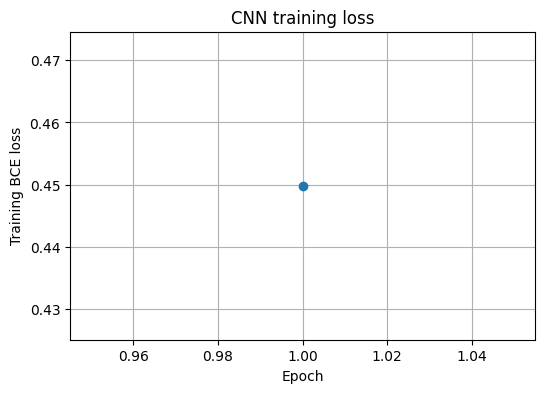

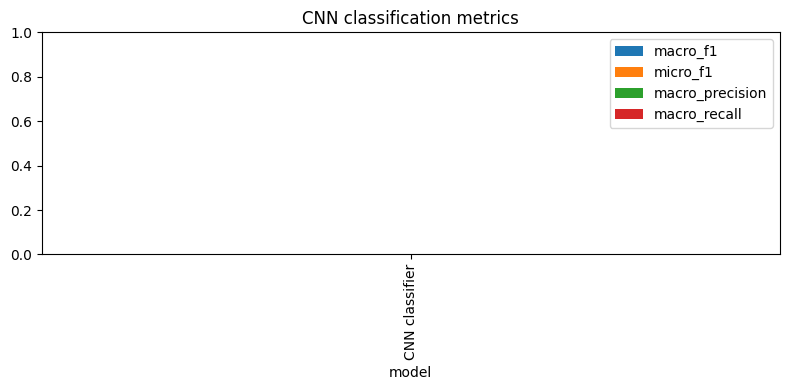

In [10]:
plt.figure(figsize=(6,4)); plt.plot(range(1,len(history)+1),history,marker="o")
plt.xlabel("Epoch"); plt.ylabel("Training BCE loss"); plt.title("CNN training loss"); plt.grid(True); plt.show()
pd.DataFrame([metrics]).set_index("model")[["macro_f1","micro_f1","macro_precision","macro_recall"]].plot(kind="bar",ylim=(0,1),figsize=(8,4),title="CNN classification metrics")
plt.tight_layout(); plt.show()

## Cell 10 — Predict labels for one test image

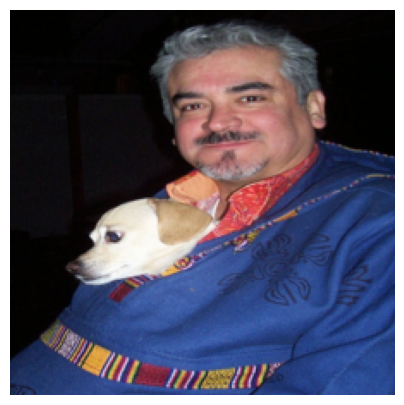

Top predicted labels: [('person', 0.372), ('car', 0.225), ('chair', 0.09), ('horse', 0.079), ('boat', 0.041)]


In [11]:
image, target = cls_test[0]
model.eval()
with torch.no_grad():
    scores=torch.sigmoid(model(image.unsqueeze(0).to(DEVICE)))[0].cpu().numpy()
top=np.argsort(scores)[::-1][:5]
plt.figure(figsize=(5,5)); plt.imshow(image.permute(1,2,0)); plt.axis("off"); plt.show()
print("Top predicted labels:",[(CLASSES[i],round(float(scores[i]),3)) for i in top])

### Notes
- Run cells in order from top to bottom.
- `QUICK_RUN=True` is a smoke test; set `False` for longer training.
- CNN output is image-level labels, not boxes. Do not compare its F1 directly with detector mAP.